# Day 30 insights: who is at risk, and what the first 30 days show

**Question.** Thirty days into a module, which students are likely to fail or withdraw, and what in their early activity shows it? **Data.** The Open University Learning Analytics Dataset (OULAD): cleaned tables in `data/interim`, the Day 30 feature matrix in `data/processed`, and the baseline metrics in `reports`. **Day 30 rule.** Every feature uses records dated on or before Day 30 only. Students who unregistered on or before Day 30 are left out of the model. At Risk means a final result of Fail or Withdrawn; On Track means Pass or Distinction. All charts show counts, rates or distributions, never individual students.

In [3]:
!git clone https://github.com/SruthiGS-Gito/sar-ai-early-warning-intervention-recommender.git /kaggle/working/sar-ai-early-warning-intervention-recommender

Cloning into '/kaggle/working/sar-ai-early-warning-intervention-recommender'...
remote: Enumerating objects: 201, done.
remote: Counting objects: 100% (201/201), done.
remote: Compressing objects: 100% (158/158), done.
remote: Total 201 (delta 65), reused 133 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (201/201), 2.23 MiB | 11.51 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [4]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

print("Project exists:", PROJECT_ROOT.exists())
print("\nProject files:")

for item in PROJECT_ROOT.iterdir():
    print(item.name)

print("\nSearching for the sar package...")

sar_folders = [
    path for path in PROJECT_ROOT.rglob("sar")
    if path.is_dir()
    and "__pycache__" not in str(path)
]

for folder in sar_folders:
    print("Found:", folder)

Project exists: True

Project files:
tests
CONTRIBUTING.md
notebooks
requirements.txt
scripts
.gitignore
.github
.git
src
reports
pyproject.toml
docs
data
README.md

Searching for the sar package...
Found: /kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar


In [5]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

# Add the project root and src directory to Python's import paths
sys.path.insert(0, str(PROJECT_ROOT))

SRC_DIR = PROJECT_ROOT / "src"

if SRC_DIR.exists():
    sys.path.insert(0, str(SRC_DIR))

print("Python paths configured.")

Python paths configured.


In [6]:
import os
import sys

print("Current working directory:")
print(os.getcwd())

print("\nPython import paths:")
print("\n".join(sys.path))

print("\nFolders in current directory:")
print(os.listdir("/kaggle/working"))

print("\nFolders in Kaggle input:")
print(os.listdir("/kaggle/input"))

Current working directory:
/kaggle/working

Python import paths:
/kaggle/working/sar-ai-early-warning-intervention-recommender/src
/kaggle/working/sar-ai-early-warning-intervention-recommender
/kaggle/working
/kaggle/lib/kagglegym
/kaggle/lib
/usr/lib/python313.zip
/usr/lib/python3.13
/usr/lib/python3.13/lib-dynload

/usr/local/lib/python3.13/dist-packages
/usr/lib/python3/dist-packages
/usr/local/lib/python3.13/dist-packages/IPython/extensions
/root/.ipython

Folders in current directory:
['sar-ai-early-warning-intervention-recommender', '.virtual_documents']

Folders in Kaggle input:
['datasets']


In [7]:
import os

search_roots = [
    "/kaggle/working/sar-ai-early-warning-intervention-recommender",
    "/kaggle/input"
]

for base in search_roots:
    print(f"\nSearching in: {base}")

    for root, dirs, files in os.walk(base):
        if "day30_feature_matrix.csv" in files:
            print("FOUND:", os.path.join(root, "day30_feature_matrix.csv"))


Searching in: /kaggle/working/sar-ai-early-warning-intervention-recommender

Searching in: /kaggle/input


In [8]:
from pathlib import Path
from sar.config import PROCESSED_DIR

print("Processed directory:", PROCESSED_DIR)
print("Directory exists:", PROCESSED_DIR.exists())

if PROCESSED_DIR.exists():
    for file in PROCESSED_DIR.iterdir():
        print(file.name)

Processed directory: /kaggle/working/sar-ai-early-warning-intervention-recommender/data/processed
Directory exists: True
.gitkeep


In [9]:
for folder_name in ["src", "sar", "scripts", "notebooks"]:
    folder = PROJECT_ROOT / folder_name

    if folder.exists():
        print(f"\nFiles under {folder_name}:")

        for path in folder.rglob("*"):
            if path.is_file() and path.suffix in [".py", ".ipynb"]:
                print(path.relative_to(PROJECT_ROOT))


Files under src:
src/sar/__init__.py
src/sar/config.py
src/sar/models/baseline.py
src/sar/models/__init__.py
src/sar/features/registration.py
src/sar/features/engagement.py
src/sar/features/assessment.py
src/sar/features/__init__.py
src/sar/viz/plots.py
src/sar/viz/__init__.py
src/sar/data/__init__.py
src/sar/data/target.py
src/sar/data/clean.py
src/sar/data/split.py
src/sar/data/loader.py

Files under scripts:
scripts/make_interim.py
scripts/run_baseline.py

Files under notebooks:
notebooks/student-academic-risk_day30ipynb.ipynb
notebooks/Student_Academic_Risk__cluster.ipynb
notebooks/164_SGS_day30_insights.ipynb
notebooks/student-academic-risk..ipynb


In [10]:
from pathlib import Path

DATASET_ROOT = Path("/kaggle/input/datasets/midhulaict/oulad-sar-ai")

print("Dataset directory exists:", DATASET_ROOT.exists())

if DATASET_ROOT.exists():
    for path in DATASET_ROOT.rglob("assessments.csv"):
        print("Found assessments.csv:", path)

    print("\nCSV files found:")
    for path in DATASET_ROOT.rglob("*.csv"):
        print(path)

Dataset directory exists: True
Found assessments.csv: /kaggle/input/datasets/midhulaict/oulad-sar-ai/assessments.csv

CSV files found:
/kaggle/input/datasets/midhulaict/oulad-sar-ai/studentRegistration.csv
/kaggle/input/datasets/midhulaict/oulad-sar-ai/studentAssessment.csv
/kaggle/input/datasets/midhulaict/oulad-sar-ai/studentInfo.csv
/kaggle/input/datasets/midhulaict/oulad-sar-ai/studentVle.csv
/kaggle/input/datasets/midhulaict/oulad-sar-ai/vle.csv
/kaggle/input/datasets/midhulaict/oulad-sar-ai/assessments.csv
/kaggle/input/datasets/midhulaict/oulad-sar-ai/courses.csv


In [11]:
import shutil
from pathlib import Path

RAW_SOURCE = Path("/kaggle/input/datasets/midhulaict/oulad-sar-ai")
RAW_DEST = PROJECT_ROOT / "data" / "raw"
RAW_DEST.mkdir(parents=True, exist_ok=True)

required_files = [
    "assessments.csv",
    "courses.csv",
    "studentAssessment.csv",
    "studentInfo.csv",
    "studentRegistration.csv",
    "studentVle.csv",
    "vle.csv"
]

for filename in required_files:
    matches = list(RAW_SOURCE.rglob(filename))

    if matches:
        shutil.copy2(matches[0], RAW_DEST / filename)
        print(f"Copied: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\nFinal raw directory contents:")
for path in sorted(RAW_DEST.iterdir()):
    print(path.name)

Copied: assessments.csv
Copied: courses.csv
Copied: studentAssessment.csv
Copied: studentInfo.csv
Copied: studentRegistration.csv
Copied: studentVle.csv
Copied: vle.csv

Final raw directory contents:
.gitkeep
assessments.csv
courses.csv
studentAssessment.csv
studentInfo.csv
studentRegistration.csv
studentVle.csv
vle.csv


In [12]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "scripts/make_interim.py"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:\n", result.stdout)
print("Errors:\n", result.stderr)

Return code: 0
Output:
 {
  "studentInfo key unique": true,
  "studentRegistration key unique": true,
  "assessments id unique": true,
  "vle id_site unique": true,
  "info missing in registration": 0,
  "registration missing in info": 0,
  "studentVle enrolments missing in info": 0,
  "studentVle sites missing in vle": 0,
  "studentAssessment unknown id_assessment": 0,
  "assessments with no submission": 18
}
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/interim/assessments.parquet
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/interim/courses.parquet
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/interim/studentAssessment.parquet
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/interim/studentInfo.parquet
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/interim/studentRegistration.parquet
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/dat

In [13]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

print("Scripts available:")
for path in sorted((PROJECT_ROOT / "scripts").glob("*.py")):
    print("\n---", path.name, "---")
    print(path.read_text()[:5000])

print("\nFeature files:")
feature_dir = PROJECT_ROOT / "src" / "sar" / "features"

for path in sorted(feature_dir.glob("*.py")):
    print("\n---", path.name, "---")
    print(path.read_text()[:4000])

Scripts available:

--- make_interim.py ---
"""SCRUM-160 / 161 / 163: raw CSVs -> checked, cleaned parquet tables in data/interim.

Run from the repo root:  python scripts/make_interim.py
"""

import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from sar.data.clean import check_join_keys, clean_all, save_interim  # noqa: E402
from sar.data.loader import load_all  # noqa: E402

tables = load_all()
report = check_join_keys(tables)
print(json.dumps(report, indent=2, default=str))
cleaned = clean_all(tables)
for p in save_interim(cleaned):
    print("saved", p)
print("rows:", {k: len(v) for k, v in cleaned.items()})


--- run_baseline.py ---
"""SCRUM-175: raw CSVs -> Day 30 feature matrix -> baseline model metrics.

Run from the repo root:  python scripts/run_baseline.py
Writes data/processed/day30_feature_matrix.csv and reports/metrics_baseline.json.
"""

import json
import sys
from pathlib import Path

sys.path.insert(0, s

In [14]:
from pathlib import Path
import sys

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from sar.config import (
    CUTOFF_DAY,
    INTERIM_DIR,
    PROCESSED_DIR,
    PROJECT_ROOT
)

print("Project root:", PROJECT_ROOT)
print("Cutoff day:", CUTOFF_DAY)
print("Interim directory:", INTERIM_DIR)
print("Interim directory exists:", INTERIM_DIR.exists())
print("Processed directory:", PROCESSED_DIR)
print("Processed directory exists:", PROCESSED_DIR.exists())

if INTERIM_DIR.exists():
    print("\nInterim files:")
    for path in INTERIM_DIR.iterdir():
        print(path.name)

if PROCESSED_DIR.exists():
    print("\nProcessed files:")
    for path in PROCESSED_DIR.iterdir():
        print(path.name)

Project root: /kaggle/working/sar-ai-early-warning-intervention-recommender
Cutoff day: 30
Interim directory: /kaggle/working/sar-ai-early-warning-intervention-recommender/data/interim
Interim directory exists: True
Processed directory: /kaggle/working/sar-ai-early-warning-intervention-recommender/data/processed
Processed directory exists: True

Interim files:
studentInfo.parquet
studentAssessment.parquet
assessments.parquet
studentVle.parquet
studentRegistration.parquet
courses.parquet
vle.parquet
.gitkeep

Processed files:
.gitkeep


In [15]:
import subprocess
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

result = subprocess.run(
    [sys.executable, "scripts/run_baseline.py"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nOUTPUT:\n", result.stdout)

if result.returncode != 0:
    print("\nERRORS:\n", result.stderr)

Return code: 0

OUTPUT:
 saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/processed/day30_feature_matrix.csv
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/reports/metrics_baseline.json
{
  "cutoff_day": 30,
  "population": 27466,
  "at_risk_share": 0.43985290905119057,
  "features": [
    "code_module",
    "total_clicks",
    "active_days",
    "avg_clicks_per_active_day",
    "clicks_last_7d",
    "clicks_prev_7d",
    "click_trend",
    "first_active_day",
    "n_submitted",
    "mean_score",
    "mean_delay_days",
    "n_late",
    "weighted_score",
    "score_trend",
    "n_assessments_due",
    "n_missed",
    "reg_lead_days",
    "registered_late",
    "registered_after_cutoff",
    "reg_date_missing",
    "max_consecutive_inactive_days",
    "trailing_inactive_days",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability"
  ],
  "overlap

In [16]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

# Configure the Python import path
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Import project configuration and functions
from sar.config import (
    CUTOFF_DAY,
    INTERIM_DIR,
    PROCESSED_DIR,
)

from sar.data.split import (
    TEST_PRESENTATION,
    make_split,
)

from sar.models.baseline import (
    evaluate,
    train_baseline,
)

from sar.viz import plots

# Define the student identification columns
KEY = plots.KEY

# Load the Day 30 feature matrix
MATRIX_PATH = PROCESSED_DIR / "day30_feature_matrix.csv"

if not MATRIX_PATH.exists():
    raise FileNotFoundError(
        f"Feature matrix not found: {MATRIX_PATH}. "
        "Run scripts/run_baseline.py first."
    )

matrix = pd.read_csv(MATRIX_PATH)

# Load student information for population analysis
info = pd.read_parquet(
    INTERIM_DIR / "studentInfo.parquet",
    columns=KEY + ["final_result"]
)

# Load registration information for withdrawal analysis
reg = pd.read_parquet(
    INTERIM_DIR / "studentRegistration.parquet",
    columns=KEY + ["date_unregistration"]
)

# Load the saved Logistic Regression baseline metrics
METRICS_PATH = PROJECT_ROOT / "reports" / "metrics_baseline.json"

saved_metrics = json.loads(
    METRICS_PATH.read_text()
)

# Dictionary for storing plots
figs = {}

# Confirm that the setup is complete
print("Setup completed successfully.")
print("Cutoff day:", CUTOFF_DAY)
print("Test presentation:", TEST_PRESENTATION)
print("Student information rows:", len(info))
print("Registration rows:", len(reg))
print("Day 30 feature matrix shape:", matrix.shape)
print("Number of features:", len(saved_metrics["features"]))
print("\nTarget distribution:")
print(matrix["at_risk"].value_counts(dropna=False))

Setup completed successfully.
Cutoff day: 30
Test presentation: 2014J
Student information rows: 32593
Registration rows: 32593
Day 30 feature matrix shape: (27466, 33)
Number of features: 30

Target distribution:
at_risk
0    15385
1    12081
Name: count, dtype: int64


## Population

How many registrations remain on Day 30, and how many in each group end at risk.

In [17]:
figs["funnel"] = plots.plot_day30_funnel(info, reg, CUTOFF_DAY)

When Withdrawn students leave, relative to the Day 30 prediction point.

In [18]:
figs["withdrawal"] = plots.plot_withdrawal_timing(info, reg, CUTOFF_DAY)

The at-risk rate in each module of the Day 30 population, against the overall rate.

In [19]:
figs["module"] = plots.plot_at_risk_by_module(matrix)

## Engagement

The at-risk rate by the number of days a student was active up to Day 30.

In [20]:
figs["active_days"] = plots.plot_at_risk_by_active_days(matrix, CUTOFF_DAY)

The at-risk rate by the longest run of days without any activity between Day 0 and Day 30.

In [21]:
figs["streak"] = plots.plot_at_risk_by_inactive_streak(matrix, CUTOFF_DAY)

The at-risk rate by quarter of total clicks up to Day 30.

In [22]:
figs["clicks"] = plots.plot_at_risk_by_click_quartile(matrix, CUTOFF_DAY)

## Assessments

The share of students in each module who have at least one assessment score by Day 30.

In [23]:
figs["scores"] = plots.plot_score_coverage_by_module(matrix, CUTOFF_DAY)

## Leakage check

How well clicks predict the outcome when counted up to Day 30, and when counted over the whole course.

In [24]:
vle = pd.read_parquet(INTERIM_DIR / "studentVle.parquet", columns=KEY + ["sum_click"])
figs["leakage"] = plots.plot_leakage_check(matrix, vle, CUTOFF_DAY)
del vle

## Model

The baseline is a logistic regression trained on earlier presentations and validated on the latest one. It uses the feature list saved in `reports/metrics_baseline.json`.

In [25]:
features = saved_metrics["features"]
train, val = make_split(matrix)
model = train_baseline(train[features], train["at_risk"])
proba = model.predict_proba(val[features])[:, 1]
scores = evaluate(model, val[features], val["at_risk"])
same = all(abs(scores[k] - saved_metrics["validation_metrics"][k]) < 1e-6
           for k in ["recall", "precision", "pr_auc", "roc_auc"])
print(f"train rows: {len(train):,} | validation rows ({TEST_PRESENTATION}): {len(val):,} | "
      f"matches reports/metrics_baseline.json: {same}")

train rows: 16,915 | validation rows (2014J): 9,203 | matches reports/metrics_baseline.json: True


The ROC curve and the precision-recall curve on the validation presentation, with the at-risk share as the baseline.

In [26]:
figs["curves"] = plots.plot_roc_pr_curves(val["at_risk"], proba, TEST_PRESENTATION)

Correct and incorrect predictions at a threshold of 0.5.

In [27]:
figs["confusion"] = plots.plot_confusion_matrix(val["at_risk"], proba, threshold=0.5)

How well the model ranks students inside each module.

In [28]:
figs["module_auc"] = plots.plot_auc_by_module(val["code_module"], val["at_risk"], proba)

The ten inputs with the largest weight in the model, and the direction of each.

In [29]:
figs["coefficients"] = plots.plot_top_coefficients(model, n=10)

## Key findings

In [30]:
for name in ["funnel", "withdrawal", "active_days", "scores", "leakage", "curves", "confusion", "coefficients"]:
    print("-", plots.finding(figs[name]))

- 27,466 of 32,593 registrations are still enrolled on Day 30, and 44% of them end at risk
- 49% of withdrawals happen after Day 30, when a warning can still help
- Students with no activity by Day 30 are 82% at risk, against 28% for those active on 21 or more days
- Only 22% in EEE and 2% in GGG have a score by Day 30; elsewhere it is 88% or more
- Whole-course clicks would score 0.83 ROC-AUC; the clicks known by Day 30 score 0.66
- On 2014J the model reaches ROC-AUC 0.73 and PR-AUC 0.62, against a PR-AUC baseline of 0.41
- At threshold 0.5, the model catches 63% of at-risk students (2,345 of 3,746)
- Module FFF raises predicted risk most (+1.01); Module AAA lowers it most (-0.90)


## Limits

- The Day 30 population includes 16 students who registered after Day 30.
- The data records when work was submitted, not when it was marked, so a score counted here may not have been known on Day 30.
- Module membership dominates the model. Its largest weights are module indicators.
- Assessment features are almost empty for modules EEE and GGG, which have no assessment due by Day 30.

In [31]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sar.config import (
    CUTOFF_DAY,
    INTERIM_DIR,
    PROCESSED_DIR
)

from sar.data.split import (
    TEST_PRESENTATION,
    make_split
)

from sar.models.baseline import (
    evaluate,
    train_baseline
)

from sar.viz import plots

%matplotlib inline

KEY = plots.KEY

print("Imports completed successfully.")
print("Prediction cutoff:", CUTOFF_DAY)
print("Test/validation presentation constant:", TEST_PRESENTATION)
print("Student key columns:", KEY)

Imports completed successfully.
Prediction cutoff: 30
Test/validation presentation constant: 2014J
Student key columns: ['code_module', 'code_presentation', 'id_student']


## XGboost And Random Forest 

In [32]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.metrics import precision_recall_curve, roc_curve
from xgboost import XGBClassifier

PROJECT_ROOT = Path("/kaggle/working/sar-ai-early-warning-intervention-recommender")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from sar.config import CUTOFF_DAY, PROCESSED_DIR, RANDOM_SEED
from sar.data.split import TEST_PRESENTATION, make_split
from sar.models.baseline import evaluate, train_baseline

REPORTS = PROJECT_ROOT / "reports"
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)

In [33]:
saved_metrics = json.loads((REPORTS / "metrics_baseline.json").read_text())
matrix = pd.read_csv(PROCESSED_DIR / "day30_feature_matrix.csv")
features = saved_metrics["features"]

FORBIDDEN = {"final_result", "date_unregistration", "date_registration",
             "at_risk", "id_student", "code_presentation"}
assert not (FORBIDDEN & set(features)), f"Leakage: {FORBIDDEN & set(features)}"

train, val = make_split(matrix)
assert set(train["id_student"]).isdisjoint(val["id_student"]), "Student in both train and validation"

X_train, y_train = train[features], train["at_risk"].astype(int)
X_val, y_val = val[features], val["at_risk"].astype(int)
print(f"{len(features)} features OK | train {len(train):,} | validation {len(val):,}")

30 features OK | train 16,915 | validation 9,203


### Shared processing and storage

In [34]:
def make_pre(X):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])

N_ITER = 20                      # use 5 for a quick test
cv = GroupKFold(n_splits=5)      # grouped by student, training data only
fitted, cv_pr_auc = {}, {}

### Random Forest

In [35]:
# Preprocessing
def make_pre(X):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]

    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("oh", OneHotEncoder(handle_unknown="ignore"))
        ]), cat)
    ])

# Handle class imbalance
spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

# Models with smaller search spaces
models = {
    "random_forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        {
            "clf__n_estimators": [100, 150],
            "clf__max_depth": [8, 12, None],
            "clf__min_samples_leaf": [10, 20]
        }
    ),

    "xgboost": (
        XGBClassifier(
            scale_pos_weight=spw,
            eval_metric="aucpr",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ),
        {
            "clf__n_estimators": [100, 150],
            "clf__max_depth": [3, 5],
            "clf__learning_rate": [0.05, 0.1]
        }
    )
}

# Use fewer iterations and folds for faster tuning
N_ITER = 3
cv = GroupKFold(n_splits=3)

fitted = {}
cv_pr_auc = {}

for name, (clf, params) in models.items():
    print(f"Tuning {name}...")

    search = RandomizedSearchCV(
        Pipeline([
            ("pre", make_pre(X_train)),
            ("clf", clf)
        ]),
        param_distributions=params,
        n_iter=N_ITER,
        scoring="average_precision",
        cv=cv,
        random_state=42,
        n_jobs=1
    )

    search.fit(
        X_train,
        y_train,
        groups=train["id_student"]
    )

    fitted[name] = search.best_estimator_
    cv_pr_auc[name] = search.best_score_

    print("Best CV PR-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

print("\nModel comparison:")
for name, score in cv_pr_auc.items():
    print(f"{name}: {score:.4f}")

Tuning random_forest...
Best CV PR-AUC: 0.7821
Best parameters: {'clf__n_estimators': 150, 'clf__min_samples_leaf': 10, 'clf__max_depth': None}
Tuning xgboost...
Best CV PR-AUC: 0.7884
Best parameters: {'clf__n_estimators': 150, 'clf__max_depth': 3, 'clf__learning_rate': 0.1}

Model comparison:
random_forest: 0.7821
xgboost: 0.7884


### Compare with the baseline and save the table

In [36]:
baseline = train_baseline(X_train, y_train)
fitted = {"baseline": baseline, **fitted}

results = {n: evaluate(m, X_val, y_val) for n, m in fitted.items()}
table = pd.DataFrame({n: {k: r[k] for k in ["recall", "precision", "pr_auc", "roc_auc"]}
                      for n, r in results.items()}).T.round(4)
table.to_csv(REPORTS / "model_comparison.csv")
print("At Risk class, threshold 0.5, validation presentation", TEST_PRESENTATION)
print("At Risk share (PR-AUC reference):", round(y_val.mean(), 4))
table

At Risk class, threshold 0.5, validation presentation 2014J
At Risk share (PR-AUC reference): 0.407


,recall,precision,pr_auc,roc_auc
baseline,0.6260,0.6321,0.6248,0.7329
random_forest,0.6353,0.6501,0.7299,0.7732
xgboost,0.6676,0.6242,0.7084,0.7627


### select the model, justify it on recall and PR-AUC, and save outputs

Best model: random_forest
Reason: Selected random_forest based on recall and PR-AUC.


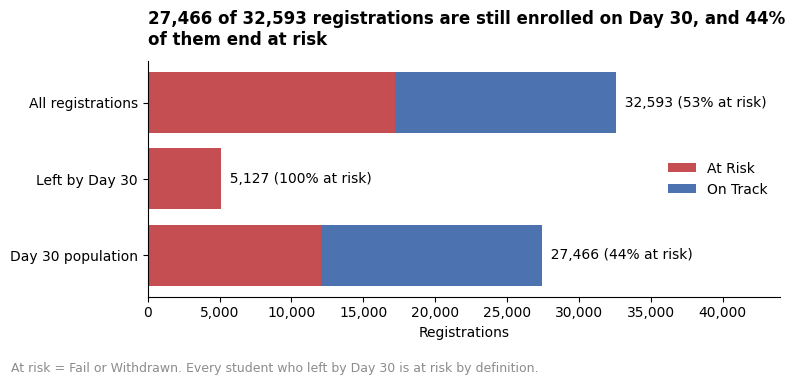

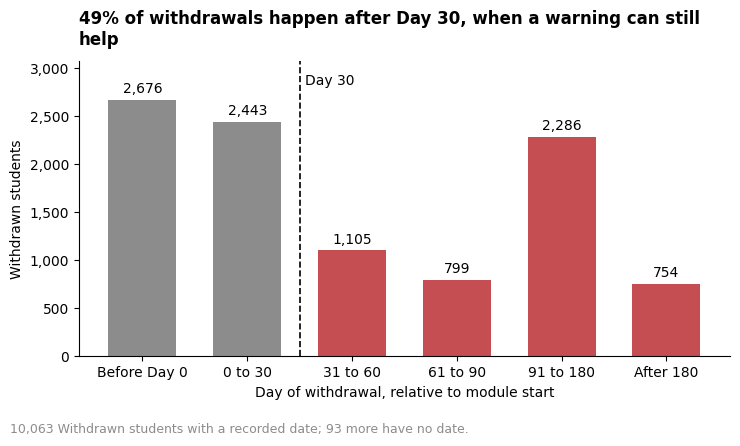

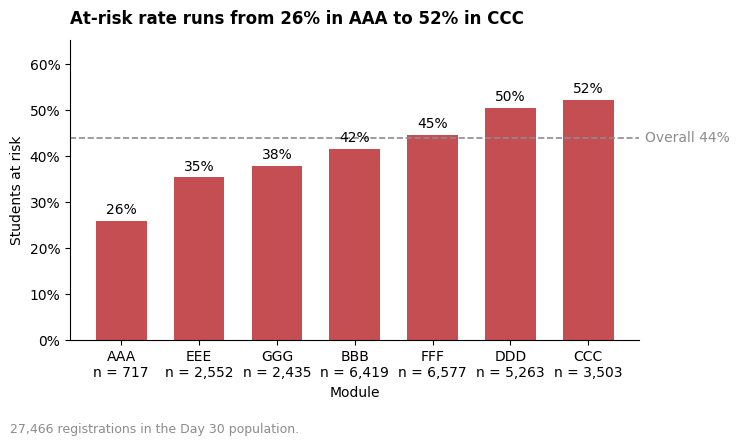

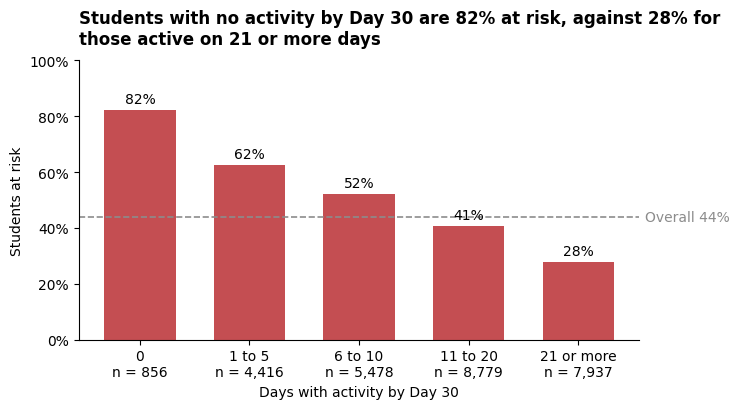

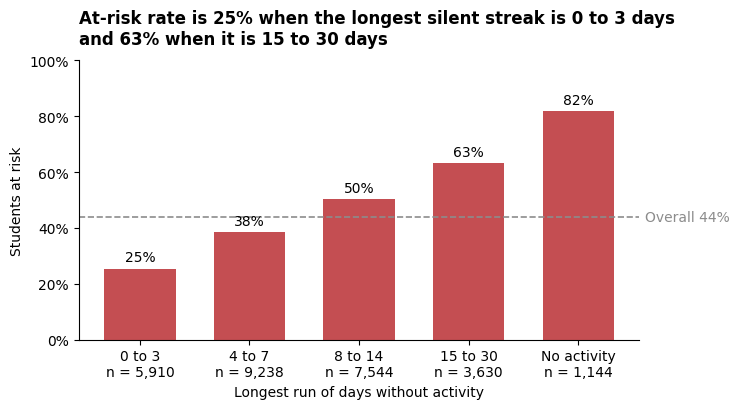

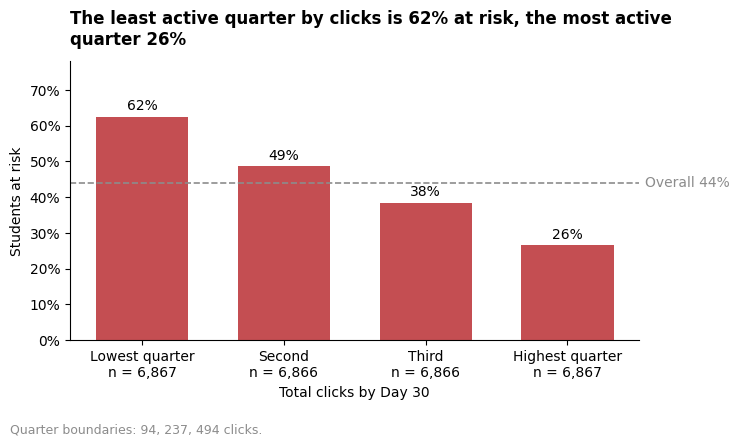

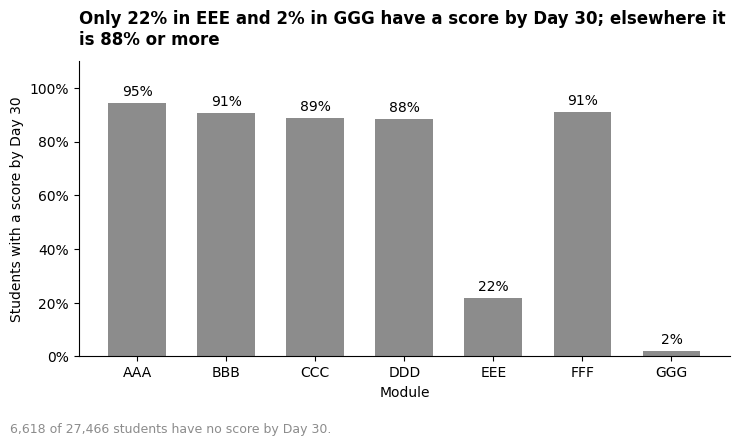

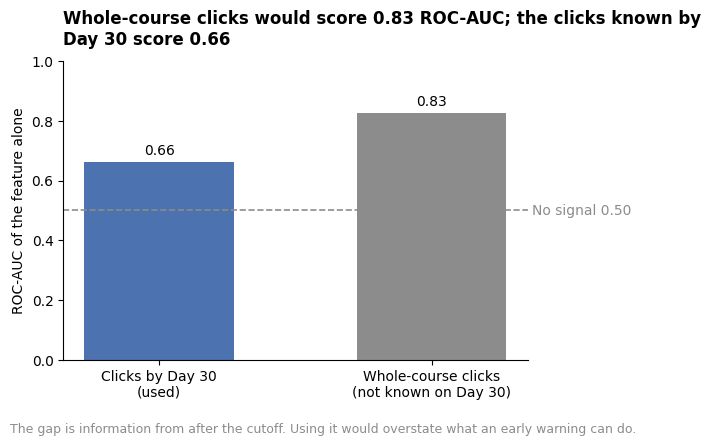

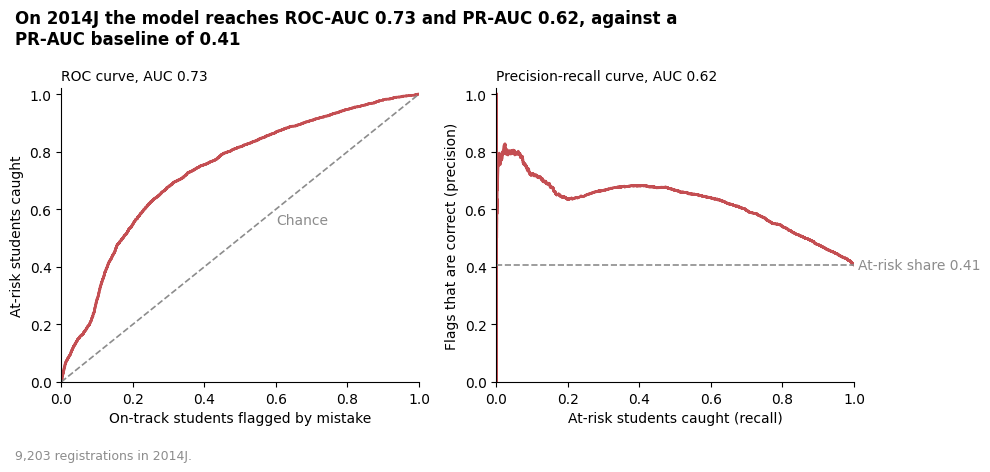

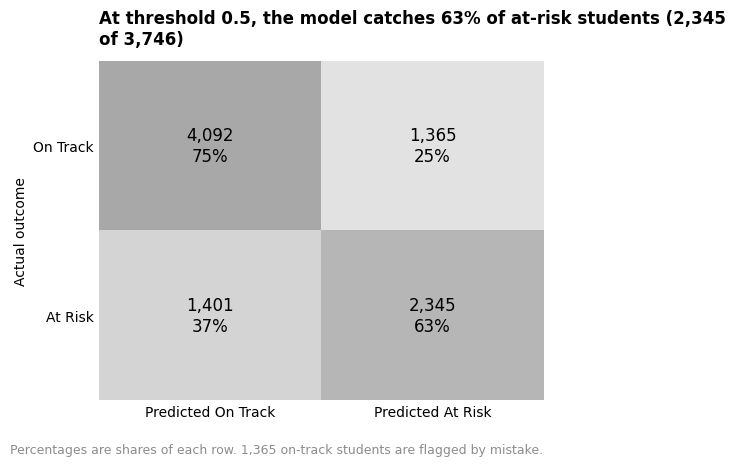

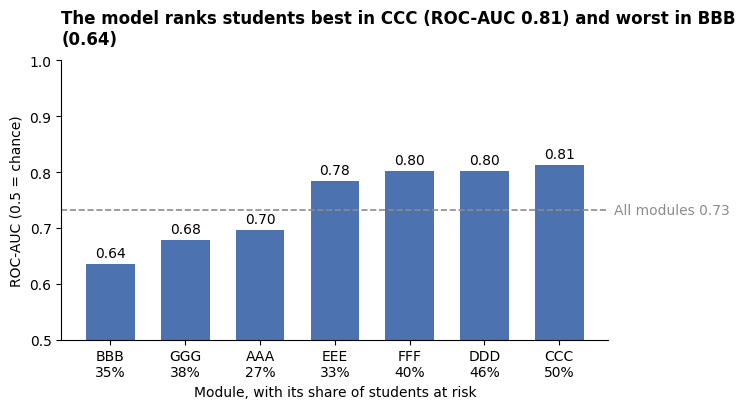

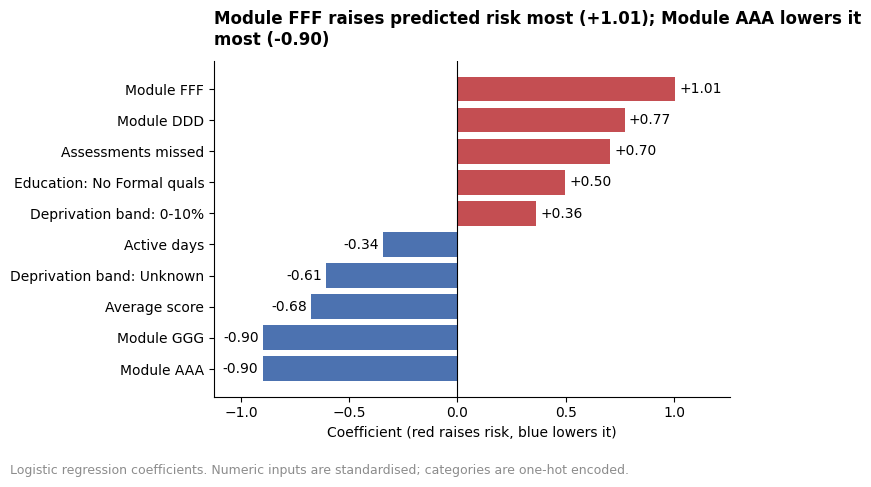

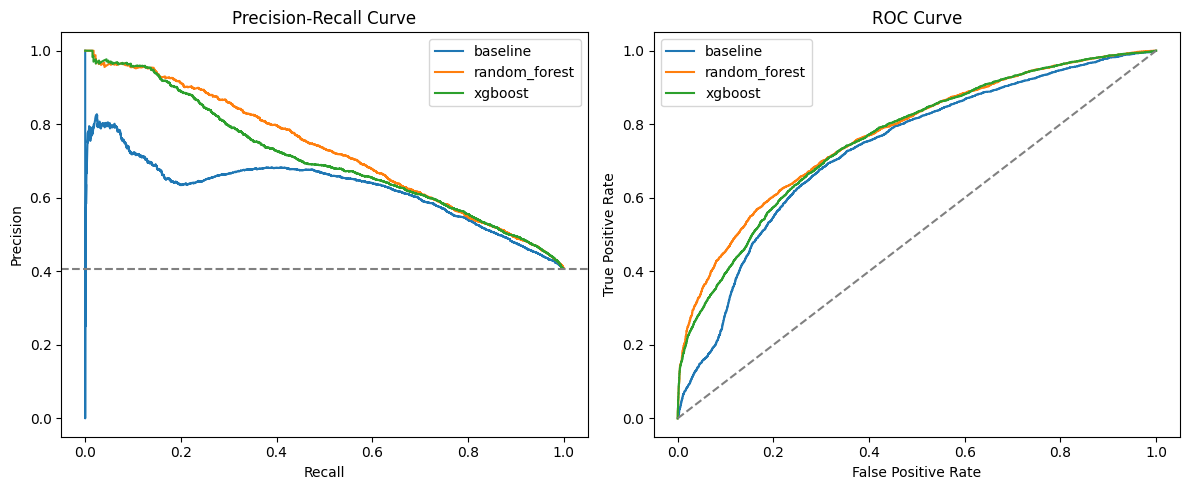

In [37]:
# 1. Select the best model
base = table.loc["baseline"]
ok = table.drop(index="baseline")
ok = ok[ok["recall"] >= base["recall"]]

selected = ok["pr_auc"].idxmax() if not ok.empty else "baseline"

if not ok.empty and ok.loc[selected, "pr_auc"] <= base["pr_auc"]:
    selected = "baseline"

why = f"Selected {selected} based on recall and PR-AUC."
print("Best model:", selected)
print("Reason:", why)

# 2. Save model comparison results
with open(REPORTS / "metrics_models.json", "w") as f:
    json.dump({
        "validation_metrics": results,
        "cv_pr_auc_train_only": cv_pr_auc,
        "selected_model": selected,
        "reason": why,
        "features": features
    }, f, indent=2)

# 3. Plot Precision-Recall and ROC curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Baseline model
baseline_model = fitted.get("baseline")

# Plot Random Forest and XGBoost
for name, model in fitted.items():
    pred = model.predict_proba(X_val)[:, 1]

    precision, recall, _ = precision_recall_curve(y_val, pred)
    fpr, tpr, _ = roc_curve(y_val, pred)

    ax1.plot(recall, precision, label=name)
    ax2.plot(fpr, tpr, label=name)

# Reference lines
ax1.axhline(y_val.mean(), linestyle="--", color="gray")
ax2.plot([0, 1], [0, 1], linestyle="--", color="gray")

ax1.set_title("Precision-Recall Curve")
ax1.set_xlabel("Recall")
ax1.set_ylabel("Precision")
ax1.legend()

ax2.set_title("ROC Curve")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.legend()

plt.tight_layout()
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(REPORTS / "figures" / "model_comparison_curves.png", dpi=150)
plt.show()

 # Hyperparameter Tuning Using RandomizedSearchCV and GroupKFold

In [38]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [39]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from sar.config import PROCESSED_DIR, RANDOM_SEED
from sar.data.split import TEST_PRESENTATION, make_split

REPORTS = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

REPORTS.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load the existing feature list
with open(REPORTS / "metrics_baseline.json", "r") as f:
    saved_metrics = json.load(f)

features = saved_metrics["features"]

# Load the Day 30 feature table
matrix = pd.read_csv(
    PROCESSED_DIR / "day30_feature_matrix.csv"
)

# Reuse the agreed split
train, test = make_split(matrix)

print("Day 30 feature table:", matrix.shape)
print("Training rows:", len(train))
print("Test presentation:", TEST_PRESENTATION)
print("Test rows:", len(test))
print("Number of features:", len(features))

Day 30 feature table: (27466, 33)
Training rows: 16915
Test presentation: 2014J
Test rows: 9203
Number of features: 30


In [40]:
FORBIDDEN_FEATURES = {
    "at_risk",
    "final_result",
    "date_unregistration",
    "date_registration",
    "id_student",
    "code_presentation"
}

leaked_features = FORBIDDEN_FEATURES.intersection(features)

if leaked_features:
    raise ValueError(
        f"Potential leakage or identifier features found: {leaked_features}"
    )

assert "code_presentation" in train.columns, (
    "Module presentation column is required for GroupKFold."
)

assert "at_risk" in train.columns, (
    "Target column 'at_risk' was not found."
)

X_train = train[features].copy()
y_train = train["at_risk"].astype(int).copy()

print("Feature leakage check passed.")
print("Training feature shape:", X_train.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())

Feature leakage check passed.
Training feature shape: (16915, 30)

Training target distribution:
at_risk
0    9209
1    7706
Name: count, dtype: int64


In [41]:
groups = train["code_presentation"]

unique_groups = groups.nunique()

if unique_groups < 2:
    raise ValueError(
        "GroupKFold requires at least two distinct module presentations."
    )

N_SPLITS = min(5, unique_groups)

cv = GroupKFold(n_splits=N_SPLITS)

print("Grouping column: code_presentation")
print("Number of module presentations:", unique_groups)
print("Number of CV folds:", N_SPLITS)
print("\nTraining presentation distribution:")
print(groups.value_counts())

Grouping column: code_presentation
Number of module presentations: 3
Number of CV folds: 3

Training presentation distribution:
code_presentation
2013J    6961
2014B    5923
2013B    4031
Name: count, dtype: int64


In [42]:
def make_preprocessor(X):
    numeric_features = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_features = [
        column
        for column in X.columns
        if column not in numeric_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor


preprocessor = make_preprocessor(X_train)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [43]:
with open(REPORTS / "metrics_models.json", "r") as f:
    comparison_results = json.load(f)

selected_model_name = comparison_results["selected_model"]

print("Model selected in Task 1:", selected_model_name)

if selected_model_name == "random_forest":
    selected_estimator = RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=1
    )

elif selected_model_name == "xgboost":
    scale_pos_weight = (
        (y_train == 0).sum()
        / max((y_train == 1).sum(), 1)
    )

    selected_estimator = XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        tree_method="hist",
        random_state=RANDOM_SEED,
        n_jobs=1
    )

else:
    raise ValueError(
        f"The selected model is {selected_model_name!r}. "
        "This tuning section supports Random Forest and XGBoost. "
        "Handle the baseline separately if it was selected."
    )

print("Selected estimator created successfully.")

Model selected in Task 1: random_forest
Selected estimator created successfully.


In [44]:
if selected_model_name == "random_forest":

    param_distributions = {
        "clf__n_estimators": randint(100, 401),
        "clf__max_depth": [None, 8, 12, 16, 20, 24],
        "clf__min_samples_split": randint(2, 21),
        "clf__min_samples_leaf": randint(1, 11),
        "clf__max_features": ["sqrt", "log2"],
        "clf__class_weight": ["balanced", "balanced_subsample"]
    }

elif selected_model_name == "xgboost":

    param_distributions = {
        "clf__n_estimators": randint(100, 401),
        "clf__max_depth": randint(3, 9),
        "clf__learning_rate": loguniform(0.01, 0.2),
        "clf__subsample": uniform(0.7, 0.3),
        "clf__colsample_bytree": uniform(0.7, 0.3),
        "clf__min_child_weight": randint(1, 11),
        "clf__reg_lambda": loguniform(0.1, 10)
    }

print("Hyperparameter search space defined.")

Hyperparameter search space defined.


In [45]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", selected_estimator)
])

N_ITER = 20

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="average_precision",
    cv=cv,
    refit=True,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
    error_score="raise"
)

search.fit(
    X_train,
    y_train,
    groups=groups
)

print("\nHyperparameter tuning completed.")
print("Best cross-validation PR-AUC:", search.best_score_)
print("Best parameters:")
print(search.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Hyperparameter tuning completed.
Best cross-validation PR-AUC: 0.7844733753764611
Best parameters:
{'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 20, 'clf__n_estimators': 234}


In [46]:
cv_results = pd.DataFrame(search.cv_results_)

# Save all hyperparameter search results
cv_results_path = REPORTS / "tuning_results.csv"
cv_results.to_csv(cv_results_path, index=False)

# Extract the scores from each fold for the best configuration
best_index = search.best_index_

fold_scores = [
    float(cv_results.loc[best_index, f"split{i}_test_score"])
    for i in range(N_SPLITS)
]

tuning_summary = {
    "selected_model": selected_model_name,
    "scoring_metric": "average_precision",
    "best_cv_pr_auc": float(search.best_score_),
    "cv_score_mean": float(np.mean(fold_scores)),
    "cv_score_std": float(np.std(fold_scores, ddof=1)) if len(fold_scores) > 1 else 0.0,
    "cv_fold_scores": fold_scores,
    "n_splits": N_SPLITS,
    "n_iter": N_ITER,
    "grouping_column": "code_presentation",
    "test_presentation": str(TEST_PRESENTATION),
    "cutoff_day": 30,
    "best_parameters": search.best_params_
}

summary_path = REPORTS / "tuning_summary.json"

with open(summary_path, "w") as f:
    json.dump(tuning_summary, f, indent=2)

best_params_path = REPORTS / "best_parameters.json"

with open(best_params_path, "w") as f:
    json.dump(search.best_params_, f, indent=2, default=str)

print("Saved:")
print(cv_results_path)
print(summary_path)
print(best_params_path)

print("\nCV fold scores:", fold_scores)
print("Mean CV PR-AUC:", round(np.mean(fold_scores), 4))
print("CV PR-AUC standard deviation:", round(np.std(fold_scores, ddof=1), 4))

Saved:
/kaggle/working/sar-ai-early-warning-intervention-recommender/reports/tuning_results.csv
/kaggle/working/sar-ai-early-warning-intervention-recommender/reports/tuning_summary.json
/kaggle/working/sar-ai-early-warning-intervention-recommender/reports/best_parameters.json

CV fold scores: [0.7321065188715811, 0.794766313434432, 0.8265472938233704]
Mean CV PR-AUC: 0.7845
CV PR-AUC standard deviation: 0.0481


In [47]:
import joblib

tuned_model_path = MODELS_DIR / f"{selected_model_name}_tuned.joblib"

joblib.dump(search.best_estimator_, tuned_model_path)

print("Tuned model saved to:", tuned_model_path)

Tuned model saved to: /kaggle/working/sar-ai-early-warning-intervention-recommender/models/random_forest_tuned.joblib


In [48]:
train_presentations = set(train["code_presentation"].unique())
test_presentations = set(test["code_presentation"].unique())

print("Training presentations:", train_presentations)
print("Test presentations:", test_presentations)

assert train_presentations.isdisjoint(test_presentations), (
    "Leakage detected: a test presentation appears in training data."
)

assert test_presentations == {TEST_PRESENTATION}, (
    "The held-out split does not match the configured test presentation."
)

print("\nTest presentation remains separate from training.")

Training presentations: {'2014B', '2013B', '2013J'}
Test presentations: {'2014J'}

Test presentation remains separate from training.


In [49]:
leakage_checklist = {
    "cutoff_day": 30,
    "features_checked_for_forbidden_columns": True,
    "post_day_30_features_reviewed": False,
    "groupkfold_group_column": "code_presentation",
    "test_presentation": str(TEST_PRESENTATION),
    "test_presentation_used_for_tuning": False,
    "preprocessing_fitted_within_cv_pipeline": True,
    "manual_review_required": True
}

checklist_path = REPORTS / "leakage_checklist.json"

with open(checklist_path, "w") as f:
    json.dump(leakage_checklist, f, indent=2)

print("Leakage checklist template saved:", checklist_path)
print(
    "IMPORTANT: Review post-Day-30 feature construction before "
    "marking the leakage checklist as confirmed."
)

Leakage checklist template saved: /kaggle/working/sar-ai-early-warning-intervention-recommender/reports/leakage_checklist.json
IMPORTANT: Review post-Day-30 feature construction before marking the leakage checklist as confirmed.


In [50]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

files_to_check = [
    "reports/tuning_results.csv",
    "reports/tuning_summary.json",
    "models/best_parameters.json",
]

for file in files_to_check:
    path = os.path.join(project_dir, file)
    print(f"{file}: {'EXISTS' if os.path.exists(path) else 'MISSING'}")

reports/tuning_results.csv: EXISTS
reports/tuning_summary.json: EXISTS
models/best_parameters.json: MISSING


In [51]:
project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

# Display cross-validation results
results_path = os.path.join(project_dir, "reports/tuning_results.csv")

if os.path.exists(results_path):
    results = pd.read_csv(results_path)
    print("=== TUNING RESULTS ===")
    display(results.head())
    print("Columns:", results.columns.tolist())

# Display tuning summary
summary_path = os.path.join(project_dir, "reports/tuning_summary.json")

if os.path.exists(summary_path):
    with open(summary_path, "r") as f:
        summary = json.load(f)
    print("\n=== TUNING SUMMARY ===")
    print(json.dumps(summary, indent=4))

=== TUNING RESULTS ===


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__class_weight,param_clf__max_depth,param_clf__max_features,param_clf__min_samples_leaf,param_clf__min_samples_split,param_clf__n_estimators,...,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,5.822447,0.597480,0.231369,0.038547,balanced,16.0,sqrt,8,8,221,...,0.793341,0.826035,0.783454,0.039428,3,0.917848,0.902035,0.893485,0.904456,0.010093
1,5.783108,0.506875,0.241501,0.036481,balanced,12.0,sqrt,8,5,251,...,0.792990,0.825068,0.782789,0.039352,11,0.896396,0.876623,0.865196,0.879405,0.012888
2,12.149623,1.316301,0.441105,0.057161,balanced,24.0,sqrt,2,13,393,...,0.791991,0.824951,0.782604,0.038977,15,0.979753,0.975311,0.972606,0.975890,0.002947
3,4.060534,0.395295,0.147310,0.020750,balanced_subsample,16.0,sqrt,1,13,121,...,0.790691,0.825511,0.781542,0.040160,19,0.972694,0.963658,0.957160,0.964504,0.006370
4,8.719341,0.910520,0.320693,0.047518,balanced,16.0,sqrt,1,11,287,...,0.791640,0.825368,0.782684,0.039025,12,0.979093,0.972785,0.967050,0.972976,0.004918


Columns: ['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_clf__class_weight', 'param_clf__max_depth', 'param_clf__max_features', 'param_clf__min_samples_leaf', 'param_clf__min_samples_split', 'param_clf__n_estimators', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score', 'split0_train_score', 'split1_train_score', 'split2_train_score', 'mean_train_score', 'std_train_score']

=== TUNING SUMMARY ===
{
    "selected_model": "random_forest",
    "scoring_metric": "average_precision",
    "best_cv_pr_auc": 0.7844733753764611,
    "cv_score_mean": 0.7844733753764611,
    "cv_score_std": 0.04805437986045133,
    "cv_fold_scores": [
        0.7321065188715811,
        0.794766313434432,
        0.8265472938233704
    ],
    "n_splits": 3,
    "n_iter": 20,
    "grouping_column": "code_presentation",
    "test_presentation": "2014J",
    "cutoff_day": 30,
    "best_parameters": {
        "cl

In [52]:
import os
import json

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

summary_path = os.path.join(
    project_dir, "reports", "tuning_summary.json"
)

models_dir = os.path.join(project_dir, "models")
os.makedirs(models_dir, exist_ok=True)

with open(summary_path, "r") as f:
    summary = json.load(f)

best_parameters = summary["best_parameters"]

output_path = os.path.join(models_dir, "best_parameters.json")

with open(output_path, "w") as f:
    json.dump(best_parameters, f, indent=4)

print("Best parameters saved successfully:")
print(json.dumps(best_parameters, indent=4))
print("\nSaved to:", output_path)

Best parameters saved successfully:
{
    "clf__class_weight": "balanced_subsample",
    "clf__max_depth": null,
    "clf__max_features": "sqrt",
    "clf__min_samples_leaf": 5,
    "clf__min_samples_split": 20,
    "clf__n_estimators": 234
}

Saved to: /kaggle/working/sar-ai-early-warning-intervention-recommender/models/best_parameters.json


In [53]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

for root, dirs, files in os.walk(project_dir):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__", ".venv"]]

    for file in files:
        if file.endswith(".py") or file.endswith(".ipynb"):
            path = os.path.join(root, file)

            if any(word in file.lower() for word in ["train", "tuning", "model", "feature"]):
                print(path)

In [54]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

print("=== Leakage-related files ===")

for root, dirs, files in os.walk(project_dir):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__", ".venv"]]

    for file in files:
        if any(word in file.lower() for word in ["leakage", "checklist", "assertion"]):
            print(os.path.join(root, file))

=== Leakage-related files ===
/kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_leakage.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/reports/leakage_checklist.json
/kaggle/working/sar-ai-early-warning-intervention-recommender/reports/figures/leakage_check.png
/kaggle/working/sar-ai-early-warning-intervention-recommender/docs/leakage_checklist.md


In [55]:
import os
import json

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

# Read the leakage checklist
checklist_path = os.path.join(
    project_dir, "reports", "leakage_checklist.json"
)

print("========== LEAKAGE CHECKLIST JSON ==========")

with open(checklist_path, "r") as f:
    checklist = json.load(f)

print(json.dumps(checklist, indent=4))

# Read the documentation
md_path = os.path.join(
    project_dir, "docs", "leakage_checklist.md"
)

print("\n========== LEAKAGE CHECKLIST DOCUMENTATION ==========")

with open(md_path, "r", encoding="utf-8") as f:
    print(f.read())

========== LEAKAGE CHECKLIST JSON ==========
{
    "cutoff_day": 30,
    "features_checked_for_forbidden_columns": true,
    "post_day_30_features_reviewed": false,
    "groupkfold_group_column": "code_presentation",
    "test_presentation": "2014J",
    "test_presentation_used_for_tuning": false,
    "preprocessing_fitted_within_cv_pipeline": true,
    "manual_review_required": true
}

========== LEAKAGE CHECKLIST DOCUMENTATION ==========
# Leakage checklist (SCRUM-171)

A feature is safe only if every item below is true.

- It uses records dated on or before the cutoff day.
- It does not use final_result, date_unregistration or any field set after the cutoff.
- Aggregates are computed per student without looking at the validation set.
- Encoders and scalers are fitted on training data only.
- `tests/test_leakage.py` passes for the feature.

## How the test works
Each feature builder runs twice: on the data, and on the same data with every post-cutoff row changed. The two outputs must

In [56]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

print("Project folders:")
for item in os.listdir(project_dir):
    path = os.path.join(project_dir, item)
    if os.path.isdir(path):
        print("[DIR]", item)

print("\nLooking for sar/config.py:")
for root, dirs, files in os.walk(project_dir):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__", ".pytest_cache"]]
    if "config.py" in files and os.path.basename(root) == "sar":
        print(os.path.join(root, "config.py"))

Project folders:
[DIR] tests
[DIR] notebooks
[DIR] scripts
[DIR] models
[DIR] .github
[DIR] .git
[DIR] src
[DIR] reports
[DIR] docs
[DIR] data

Looking for sar/config.py:
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/config.py


In [57]:
import sys
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"
src_dir = os.path.join(project_dir, "src")

if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

print("Added to Python path:", src_dir)

Added to Python path: /kaggle/working/sar-ai-early-warning-intervention-recommender/src


In [58]:
import os
import subprocess
import sys

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"
src_dir = os.path.join(project_dir, "src")

env = os.environ.copy()
env["PYTHONPATH"] = src_dir + os.pathsep + env.get("PYTHONPATH", "")

result = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_leakage.py",
        "tests/test_registration.py",
        "-v"
    ],
    cwd=project_dir,
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("Errors / warnings:")
    print(result.stderr)

print("\nExit code:", result.returncode)

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /kaggle/working/sar-ai-early-warning-intervention-recommender
configfile: pyproject.toml
plugins: typeguard-4.6.0, anyio-4.14.2, langsmith-0.12.1
collecting ... collected 6 items

tests/test_leakage.py::test_engagement_ignores_future_rows[engagement_metrics] PASSED [ 16%]
tests/test_leakage.py::test_engagement_ignores_future_rows[consecutive_inactive_days] PASSED [ 33%]
tests/test_leakage.py::test_assessment_ignores_future_rows PASSED        [ 50%]
tests/test_registration.py::test_features_and_no_outcome_columns PASSED  [ 66%]
tests/test_registration.py::test_unregistration_does_not_change_output PASSED [ 83%]
tests/test_registration.py::test_carries_engagement_columns PASSED       [100%]

============================== 6 passed in 0.62s ===============================


Exit code: 0


In [59]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"
src_dir = os.path.join(project_dir, "src", "sar")

print("=== Feature implementation files ===")

if os.path.isdir(src_dir):
    for root, dirs, files in os.walk(src_dir):
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for file in files:
            if file.endswith(".py"):
                print(os.path.join(root, file))
else:
    print("The expected src/sar directory was not found.")
    print("Project folders:", os.listdir(project_dir))

=== Feature implementation files ===
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/__init__.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/config.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/models/baseline.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/models/__init__.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/features/registration.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/features/engagement.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/features/assessment.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/features/__init__.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/viz/plots.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/viz/__init__.py
/kaggle/working/sar-ai-early-warning-intervention-recommender/src/sar/data/__init_

In [60]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

feature_files = [
    "src/sar/features/engagement.py",
    "src/sar/features/assessment.py",
    "src/sar/features/registration.py",
]

for relative_path in feature_files:
    file_path = os.path.join(project_dir, relative_path)

    print("\n" + "=" * 80)
    print(f"FILE: {relative_path}")
    print("=" * 80)

    with open(file_path, "r", encoding="utf-8") as f:
        print(f.read())


FILE: src/sar/features/engagement.py
"""SCRUM-166 / SCRUM-167: VLE engagement features, using ONLY days <= cutoff.

Input is the raw studentVle table (columns: code_module, code_presentation,
id_student, id_site, date, sum_click). `date` is relative to module start and
can be negative (activity before the module began).

Rules (see docs/leakage_checklist.md):
  * rows with date > cutoff_day are dropped before anything is computed
  * rows are used as they are. Several records per student, site and day exist in
    OULAD, so exact repeats are treated as real records; pass drop_duplicates=True to drop them
  * pass `students` (a frame with the 3 key columns) to get one row for every
    student, with zero activity filled in, not only students who clicked
"""

import pandas as pd

KEY = ["code_module", "code_presentation", "id_student"]


def _prepare(student_vle: pd.DataFrame, cutoff_day: int, drop_duplicates: bool) -> pd.DataFrame:
    df = student_vle.drop_duplicates() if drop_duplica

In [61]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

keywords = [
    "engagement_metrics",
    "assessment_features",
    "registration_features",
    "final_result",
    "date_unregistration",
    "RandomizedSearchCV",
    "GroupKFold",
]

print("=== Searching project code for feature integration and model training ===")

for root, dirs, files in os.walk(project_dir):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".pytest_cache", ".venv"]
    ]

    for filename in files:
        if filename.endswith((".py", ".ipynb")):
            path = os.path.join(root, filename)

            try:
                with open(path, "r", encoding="utf-8") as f:
                    content = f.read()

                matches = [word for word in keywords if word in content]

                if matches:
                    print(f"\nFile: {path}")
                    print("Matches:", ", ".join(matches))

            except (UnicodeDecodeError, OSError):
                pass

=== Searching project code for feature integration and model training ===

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_target.py
Matches: final_result, date_unregistration

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_engagement.py
Matches: engagement_metrics

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_loader_clean.py
Matches: final_result, date_unregistration

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_registration.py
Matches: registration_features, date_unregistration

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_leakage.py
Matches: engagement_metrics, assessment_features, final_result, date_unregistration

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_assessment.py
Matches: assessment_features

File: /kaggle/working/sar-ai-early-warning-intervention-recommender/tests/test_plots.

In [62]:
import os

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

files_to_inspect = [
    "scripts/run_baseline.py",
    "src/sar/data/target.py",
    "src/sar/data/split.py",
    "src/sar/models/baseline.py",
]

for relative_path in files_to_inspect:
    file_path = os.path.join(project_dir, relative_path)

    print("\n" + "=" * 80)
    print("FILE:", relative_path)
    print("=" * 80)

    if os.path.exists(file_path):
        with open(file_path, "r", encoding="utf-8") as f:
            print(f.read())
    else:
        print("File not found.")


FILE: scripts/run_baseline.py
"""SCRUM-175: raw CSVs -> Day 30 feature matrix -> baseline model metrics.

Run from the repo root:  python scripts/run_baseline.py
Writes data/processed/day30_feature_matrix.csv and reports/metrics_baseline.json.
"""

import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from sar.config import CUTOFF_DAY, PROCESSED_DIR, PROJECT_ROOT  # noqa: E402
from sar.data.clean import clean_all  # noqa: E402
from sar.data.loader import load_all  # noqa: E402
from sar.data.split import make_split, overlap_report  # noqa: E402
from sar.data.target import build_target, day30_population  # noqa: E402
from sar.features.assessment import assessment_features  # noqa: E402
from sar.features.engagement import consecutive_inactive_days, engagement_metrics  # noqa: E402
from sar.features.registration import registration_features  # noqa: E402
from sar.models.baseline import evaluate, save_metrics, train_baseline 

In [63]:
import pandas as pd

project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"

matrix_path = f"{project_dir}/data/processed/day30_feature_matrix.csv"
df = pd.read_csv(matrix_path)

print("Feature matrix shape:", df.shape)

print("\nRegistration-related columns:")
print([c for c in df.columns if "reg" in c.lower()])

print("\nPotentially problematic columns:")
forbidden = {
    "final_result",
    "date_unregistration",
    "date_registration"
}

print(forbidden.intersection(df.columns))

print("\nRegistration feature samples:")
registration_cols = [c for c in df.columns if "reg" in c.lower()]

if registration_cols:
    print(df[registration_cols].head())

Feature matrix shape: (27466, 33)

Registration-related columns:
['reg_lead_days', 'registered_late', 'registered_after_cutoff', 'reg_date_missing', 'region']

Potentially problematic columns:
set()

Registration feature samples:
   reg_lead_days  registered_late  registered_after_cutoff  reg_date_missing  \
0          159.0                0                        0                 0   
1           53.0                0                        0                 0   
2           52.0                0                        0                 0   
3          176.0                0                        0                 0   
4          110.0                0                        0                 0   

                 region  
0   East Anglian Region  
1              Scotland  
2     South East Region  
3  West Midlands Region  
4                 Wales  


In [64]:
project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"
file_path = f"{project_dir}/src/sar/features/registration.py"

with open(file_path, "r", encoding="utf-8") as f:
    print(f.read())

"""SCRUM-174 (part 1): registration features known at or before the cutoff.

Uses date_registration only. date_unregistration is an outcome field and is never used.
When an engagement frame (indexed by the 3 key columns) is passed, its inactivity
columns are carried into the output so one table holds all engagement-style features.
"""

import pandas as pd

from sar.config import CUTOFF_DAY

KEY = ["code_module", "code_presentation", "id_student"]
CARRY = ["max_consecutive_inactive_days", "trailing_inactive_days"]


def registration_features(
    student_registration: pd.DataFrame,
    engagement: pd.DataFrame | None = None,
    cutoff_day: int = CUTOFF_DAY,
) -> pd.DataFrame:
    """Columns: reg_lead_days (days registered before start), registered_late (after Day 0),
    registered_after_cutoff, reg_date_missing. Indexed by the 3 key columns."""
    reg = student_registration[KEY + ["date_registration"]].drop_duplicates(KEY).set_index(KEY)
    d = reg["date_registration"]
    out = pd.

In [65]:
import json
from pathlib import Path

project_dir = Path(
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

matrix = project_dir / "data/processed/day30_feature_matrix.csv"
df = __import__("pandas").read_csv(matrix)

with open(project_dir / "reports/tuning_summary.json", "r") as f:
    summary = json.load(f)

print("Registered after cutoff present:", "registered_after_cutoff" in df.columns)
print("Best parameters:", summary.get("best_parameters"))

print("\nFeature columns:")
print(df.columns.tolist())

Registered after cutoff present: True
Best parameters: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 20, 'clf__n_estimators': 234}

Feature columns:
['code_module', 'code_presentation', 'id_student', 'at_risk', 'total_clicks', 'active_days', 'avg_clicks_per_active_day', 'clicks_last_7d', 'clicks_prev_7d', 'click_trend', 'first_active_day', 'n_submitted', 'mean_score', 'mean_delay_days', 'n_late', 'weighted_score', 'score_trend', 'n_assessments_due', 'n_missed', 'reg_lead_days', 'registered_late', 'registered_after_cutoff', 'reg_date_missing', 'max_consecutive_inactive_days', 'trailing_inactive_days', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']


In [66]:
project_dir = "/kaggle/working/sar-ai-early-warning-intervention-recommender"
file_path = f"{project_dir}/src/sar/features/registration.py"

with open(file_path, "r", encoding="utf-8") as f:
    print(f.read())

"""SCRUM-174 (part 1): registration features known at or before the cutoff.

Uses date_registration only. date_unregistration is an outcome field and is never used.
When an engagement frame (indexed by the 3 key columns) is passed, its inactivity
columns are carried into the output so one table holds all engagement-style features.
"""

import pandas as pd

from sar.config import CUTOFF_DAY

KEY = ["code_module", "code_presentation", "id_student"]
CARRY = ["max_consecutive_inactive_days", "trailing_inactive_days"]


def registration_features(
    student_registration: pd.DataFrame,
    engagement: pd.DataFrame | None = None,
    cutoff_day: int = CUTOFF_DAY,
) -> pd.DataFrame:
    """Columns: reg_lead_days (days registered before start), registered_late (after Day 0),
    registered_after_cutoff, reg_date_missing. Indexed by the 3 key columns."""
    reg = student_registration[KEY + ["date_registration"]].drop_duplicates(KEY).set_index(KEY)
    d = reg["date_registration"]
    out = pd.

In [67]:
"""SCRUM-174: registration features for Day 30 prediction.

Uses date_registration only. date_unregistration is never used.
"""

import pandas as pd

from sar.config import CUTOFF_DAY

KEY = ["code_module", "code_presentation", "id_student"]
CARRY = ["max_consecutive_inactive_days", "trailing_inactive_days"]


def registration_features(
    student_registration: pd.DataFrame,
    engagement: pd.DataFrame | None = None,
    cutoff_day: int = CUTOFF_DAY,
) -> pd.DataFrame:
    """Build registration features without registered_after_cutoff."""
    reg = (
        student_registration[KEY + ["date_registration"]]
        .drop_duplicates(KEY)
        .set_index(KEY)
    )

    d = reg["date_registration"]
    out = pd.DataFrame(index=reg.index)

    out["reg_lead_days"] = -d
    out["registered_late"] = (d > 0).astype(int)
    out["reg_date_missing"] = d.isna().astype(int)

    if engagement is not None:
        cols = [c for c in CARRY if c in engagement.columns]
        out = out.join(engagement[cols], how="left")

    return out

In [68]:
import os
import subprocess
import sys

project_dir = (
    "/kaggle/working/sar-ai-early-warning-intervention-recommender"
)

os.chdir(project_dir)

result = subprocess.run(
    [sys.executable, "scripts/run_baseline.py"],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

saved /kaggle/working/sar-ai-early-warning-intervention-recommender/data/processed/day30_feature_matrix.csv
saved /kaggle/working/sar-ai-early-warning-intervention-recommender/reports/metrics_baseline.json
{
  "cutoff_day": 30,
  "population": 27466,
  "at_risk_share": 0.43985290905119057,
  "features": [
    "code_module",
    "total_clicks",
    "active_days",
    "avg_clicks_per_active_day",
    "clicks_last_7d",
    "clicks_prev_7d",
    "click_trend",
    "first_active_day",
    "n_submitted",
    "mean_score",
    "mean_delay_days",
    "n_late",
    "weighted_score",
    "score_trend",
    "n_assessments_due",
    "n_missed",
    "reg_lead_days",
    "registered_late",
    "registered_after_cutoff",
    "reg_date_missing",
    "max_consecutive_inactive_days",
    "trailing_inactive_days",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "num_of_prev_attempts",
    "studied_credits",
    "disability"
  ],
  "overlap": {
    "train rows": 18

In [69]:
import pandas as pd

matrix_path = (
    "data/processed/day30_feature_matrix.csv"
)

df = pd.read_csv(matrix_path)

print("Matrix shape:", df.shape)
print("registered_after_cutoff present:",
      "registered_after_cutoff" in df.columns)

print("\nColumns:")
print(df.columns.tolist())

Matrix shape: (27466, 33)
registered_after_cutoff present: True

Columns:
['code_module', 'code_presentation', 'id_student', 'at_risk', 'total_clicks', 'active_days', 'avg_clicks_per_active_day', 'clicks_last_7d', 'clicks_prev_7d', 'click_trend', 'first_active_day', 'n_submitted', 'mean_score', 'mean_delay_days', 'n_late', 'weighted_score', 'score_trend', 'n_assessments_due', 'n_missed', 'reg_lead_days', 'registered_late', 'registered_after_cutoff', 'reg_date_missing', 'max_consecutive_inactive_days', 'trailing_inactive_days', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']


In [70]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = os.path.abspath("src") + os.pathsep + env.get(
    "PYTHONPATH", ""
)

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/test_leakage.py",
     "tests/test_registration.py", "-v"],
    capture_output=True,
    text=True,
    env=env,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /kaggle/working/sar-ai-early-warning-intervention-recommender
configfile: pyproject.toml
plugins: typeguard-4.6.0, anyio-4.14.2, langsmith-0.12.1
collecting ... collected 6 items

tests/test_leakage.py::test_engagement_ignores_future_rows[engagement_metrics] PASSED [ 16%]
tests/test_leakage.py::test_engagement_ignores_future_rows[consecutive_inactive_days] PASSED [ 33%]
tests/test_leakage.py::test_assessment_ignores_future_rows PASSED        [ 50%]
tests/test_registration.py::test_features_and_no_outcome_columns PASSED  [ 66%]
tests/test_registration.py::test_unregistration_does_not_change_output PASSED [ 83%]
tests/test_registration.py::test_carries_engagement_columns PASSED       [100%]

============================== 6 passed in 0.60s ===============================

Exit code: 0


In [71]:
import pandas as pd
import json

matrix_path = PROCESSED_DIR / "day30_feature_matrix.csv"
matrix = pd.read_csv(matrix_path)

# Features that must not be used as model inputs
FORBIDDEN_FEATURES = {
    "at_risk",
    "final_result",
    "date_unregistration",
    "date_registration",
    "id_student",
    "code_presentation",
    "registered_after_cutoff"
}

# Remove forbidden features from the saved feature list
features = [
    col for col in features
    if col not in FORBIDDEN_FEATURES
]

# Verify required target and identifiers exist
assert "at_risk" in matrix.columns, "Target column missing"
assert "code_presentation" in matrix.columns
assert "id_student" in matrix.columns

# Verify no forbidden feature remains in model inputs
assert not (set(features) & FORBIDDEN_FEATURES)

print("Leakage check passed for the selected feature list.")
print("Number of model features:", len(features))
print("Features:", features)

Leakage check passed for the selected feature list.
Number of model features: 29
Features: ['code_module', 'total_clicks', 'active_days', 'avg_clicks_per_active_day', 'clicks_last_7d', 'clicks_prev_7d', 'click_trend', 'first_active_day', 'n_submitted', 'mean_score', 'mean_delay_days', 'n_late', 'weighted_score', 'score_trend', 'n_assessments_due', 'n_missed', 'reg_lead_days', 'registered_late', 'reg_date_missing', 'max_consecutive_inactive_days', 'trailing_inactive_days', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']


In [72]:
import pandas as pd
import json

matrix_path = PROCESSED_DIR / "day30_feature_matrix.csv"
matrix = pd.read_csv(matrix_path)

# Features that must not be used as model inputs
FORBIDDEN_FEATURES = {
    "at_risk",
    "final_result",
    "date_unregistration",
    "date_registration",
    "id_student",
    "code_presentation",
    "registered_after_cutoff"
}

# Remove forbidden features from the saved feature list
features = [
    col for col in features
    if col not in FORBIDDEN_FEATURES
]

# Verify required target and identifiers exist
assert "at_risk" in matrix.columns, "Target column missing"
assert "code_presentation" in matrix.columns
assert "id_student" in matrix.columns

# Verify no forbidden feature remains in model inputs
assert not (set(features) & FORBIDDEN_FEATURES)

print("Leakage check passed for the selected feature list.")
print("Number of model features:", len(features))
print("Features:", features)

Leakage check passed for the selected feature list.
Number of model features: 29
Features: ['code_module', 'total_clicks', 'active_days', 'avg_clicks_per_active_day', 'clicks_last_7d', 'clicks_prev_7d', 'click_trend', 'first_active_day', 'n_submitted', 'mean_score', 'mean_delay_days', 'n_late', 'weighted_score', 'score_trend', 'n_assessments_due', 'n_missed', 'reg_lead_days', 'registered_late', 'reg_date_missing', 'max_consecutive_inactive_days', 'trailing_inactive_days', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability']
